<a href="https://colab.research.google.com/github/SalmaAnindhia/PemMes_25_Salma/blob/main/JS10_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

Load Data dan Visualisasi

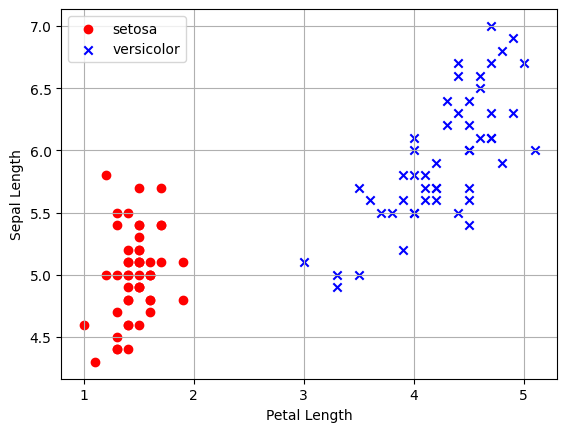

In [ ]:
df = pd.read_csv('/content/Iris.csv')

setosa = df[df['Species'] == 'Iris-setosa']
versicolor = df[df['Species'] == 'Iris-versicolor']
virginica = df[df['Species'] == 'Iris-virginica']

a, b = 'PetalLengthCm', 'SepalLengthCm'

plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='versicolor')

plt.xlabel('Petal Length')
plt.ylabel('Sepal Length')
plt.legend(loc='upper left')
plt.grid()
plt.show()

Membuat Kelas Perceptron

In [ ]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):

        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

Pilih Data dan Encoding Label

In [23]:
y = df.iloc[0:100, 5].values
y = np.where(y == 'Iris-setosa', -1, 1)
X = df.iloc[0:100, [1, 4]].values

Fitting Model

In [24]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

Visualisasi Nilai Error Per Epoch

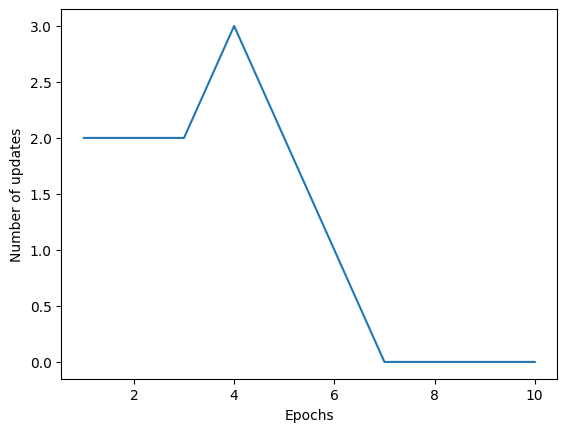

In [25]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.show()

Visualisasi Decision Boundary

/tmp/ipykernel_1694/456691628.py:20: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)


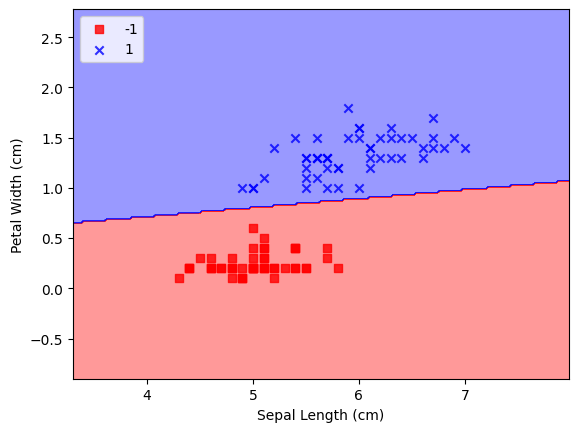

In [27]:
# 1. Load data & perbaikan label (dari perbaikan sebelumnya)
df = pd.read_csv('/content/Iris.csv')
y = df.iloc[0:100, 5].values
y = np.where(y == 'Iris-setosa', -1, 1)
X = df.iloc[0:100, [1, 4]].values
# 2. Definisi class Perceptron (sudah kamu punya)
# 3. Training
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)
# 4. Definisi fungsi plot_decision_regions (sudah kamu punya)
# 5. PANGGIL fungsinya
plot_decision_regions(X, y, classifier=ppn)
plt.legend(loc='upper left')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.show()